# Классификация: вероятность, деревья и переобучение

ФПМИ.Будущее · ИИ · Прекурс · Занятие 9

В классификации модель выбирает один из классов. Сегодня разберём две базовые модели:

- логистическая регрессия строит линейный score и превращает его в вероятность;
- решающее дерево последовательно задаёт вопросы о признаках.

Главный вопрос второй половины урока: почему более сложная модель лучше запоминает train, но может хуже работать на новых объектах?


## 1. Данные и честная проверка

Например, письмо бывает спамом или обычным письмом. Ответ — **класс**, а не произвольное число, как в регрессии.

Для наглядности возьмём два класса точек на плоскости. `X` — таблица из двух признаков, `y` — правильные метки `0` и `1`. Одна строка `X` соответствует одному ответу `y`.

Данные генерируются локально — скачивать ничего не нужно.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

plt.style.use("dark_background")
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 16,
    "figure.facecolor": "#111827",
    "axes.facecolor": "#111827",
    "savefig.facecolor": "#111827",
    "figure.dpi": 120,
})

X, y = make_moons(n_samples=350, noise=0.28, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

print("Все данные:", X.shape, y.shape)
print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)
print("Классы в train:", np.bincount(y_train))
print("Классы в test:", np.bincount(y_test))


Все данные: (350, 2) (350,)
Train: (245, 2) (245,)
Test: (105, 2) (105,)
Классы в train: [122 123]
Классы в test: [53 52]


![Train используется для обучения, test — для честной проверки](attachment:train-test.png)


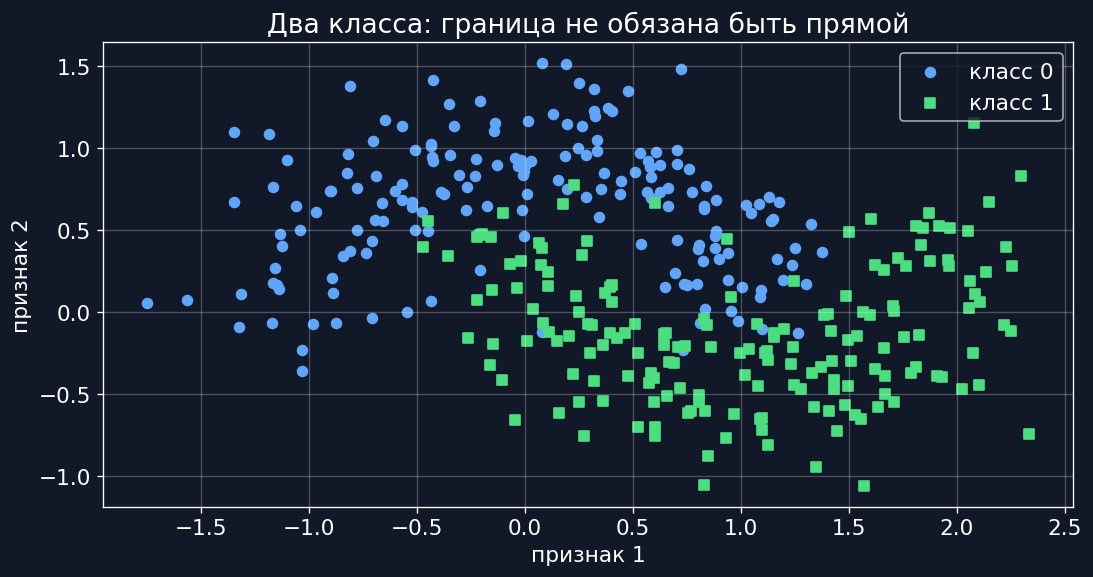

In [2]:
plt.figure(figsize=(9, 4.7), layout="constrained")
plt.scatter(X[y == 0, 0], X[y == 0, 1], color="#60A5FA", label="класс 0", s=35)
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="#4ADE80", label="класс 1", marker="s", s=35)
plt.xlabel("признак 1")
plt.ylabel("признак 2")
plt.title("Два класса: граница не обязана быть прямой")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


`stratify=y` сохраняет примерно одинаковую долю классов в train и test. `random_state=42` позволяет повторить тот же эксперимент. Модель обучается только на train; test изображает новые данные.


## 2. Логистическая регрессия

Логистическая регрессия сначала считает линейный **score** — число `z = w₁x₁ + w₂x₂ + b`. Коэффициенты `w` и `b` подбираются во время `fit` по обучающим данным.

Например, `z = 0` превращается в вероятность `0.5`, а `z = 2` — примерно в `0.88`. Это делает **сигмоида**: она переводит любое конечное число в интервал `(0, 1)`.


![Линейный score, сигмоида, вероятность и класс](attachment:logistic.png)


### Как понять, что коэффициенты стали лучше

Допустим, правильный класс объекта — `1`. Вероятность `0.9` лучше, чем `0.6`, а `0.1` — уверенная ошибка. Нужна величина, которая это учитывает: **log loss**, или логарифмическая потеря.

- Если `y = 1`, потеря равна `−log(p)`.
- Если `y = 0`, потеря равна `−log(1 − p)`.

Здесь `log` — натуральный логарифм. Мы берём минус логарифм вероятности **правильного** класса: чем она меньше, тем сильнее штраф. Для всей обучающей выборки усредняем потери объектов. **Меньше — лучше.**


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def binary_log_loss(y_true, p):
    y_true = np.asarray(y_true)
    p = np.clip(p, 1e-12, 1 - 1e-12)  # Чтобы не считать log(0).
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))


print("Правильный класс — 1:")
for p in [0.9, 0.6, 0.1]:
    print(f"p = {p:.1f} → log loss = {binary_log_loss(1, p):.3f}")


Правильный класс — 1:
p = 0.9 → log loss = 0.105
p = 0.6 → log loss = 0.511
p = 0.1 → log loss = 2.303


### Как уменьшать log loss

Обучение повторяет цикл: **вероятности → потеря → поправка коэффициентов → новые вероятности**. Признаки и правильные ответы при этом остаются прежними.

**Градиент** показывает направление самого быстрого роста потери в текущей точке. Поэтому для спуска делаем небольшой шаг в противоположную сторону:

```text
новые параметры = старые параметры − learning_rate × градиент
```

`learning_rate` задаёт размер шага. Слишком маленький шаг замедляет обучение, слишком большой может увеличить потерю.

Возьмём отдельный мини-пример с одним признаком: `z = w·x + b`. Так оба изменяемых параметра можно показать на одной плоскости. Ниже — готовые формулы градиента для среднего log loss; выводить их для этого примера не требуется.


In [4]:
# Учебные данные с одним признаком; это отдельный мини-пример.
x_gd = np.array([-2, -1.5, -1, -0.5, 0.5, 1, 1.5, 2])
y_gd = np.array([ 0,    0,  1,    0,   1, 0,   1, 1])

w, b = -2.0, 2.0
learning_rate = 0.4
gd_path = [(w, b)]

for step in range(40):
    p = sigmoid(w * x_gd + b)
    grad_w = np.mean((p - y_gd) * x_gd)
    grad_b = np.mean(p - y_gd)
    w = w - learning_rate * grad_w
    b = b - learning_rate * grad_b
    gd_path.append((w, b))

gd_path = np.array(gd_path)
gd_losses = np.array([
    binary_log_loss(y_gd, sigmoid(weight * x_gd + bias))
    for weight, bias in gd_path
])

print(f"До обучения: w = {gd_path[0, 0]:.2f}, b = {gd_path[0, 1]:.2f}")
print(f"После 40 шагов: w = {w:.2f}, b = {b:.2f}")
print(f"Log loss: {gd_losses[0]:.3f} → {gd_losses[-1]:.3f}")


До обучения: w = -2.00, b = 2.00
После 40 шагов: w = 0.96, b = 0.09
Log loss: 2.315 → 0.530


![Шаги градиентного спуска по log loss: изменение параметров и уменьшение потери](attachment:gradient-descent.png)


Слева каждая точка — **пара параметров `(w, b)`**, а не объект из данных. Линии соединяют пары с одинаковой потерей. Жёлтый путь показывает обновления параметров; зелёная точка — результат после 40 шагов. Справа — потери на тех же шагах.

Рисунок соответствует запуску выше: `learning_rate = 0.4`, 40 шагов. Потеря снизилась примерно с `2.315` до `0.530`. Она не обязана стать нулевой: классы в этом примере перемешаны, одна граница не разделяет их идеально.

### Возвращаемся к sklearn

`fit` подбирает коэффициенты, уменьшая функцию потерь на train. Наш пример показывает простой градиентный спуск без регуляризации. У `LogisticRegression` по умолчанию другой оптимизатор — L-BFGS — и дополнительный штраф за большие коэффициенты. Их детали здесь не нужны: общий смысл обучения уже виден.


In [5]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

print("Классы модели:", logreg.classes_)
print("Коэффициенты:", logreg.coef_)
print("Свободный коэффициент:", logreg.intercept_)


Классы модели: [0 1]
Коэффициенты: [[ 1.12244843 -3.27690205]]
Свободный коэффициент: [0.17987229]


У бинарной модели `predict_proba` возвращает две колонки. Их порядок совпадает с `model.classes_`. Для классов `[0, 1]` вероятность класса `1` лежит во второй колонке.


In [6]:
proba = logreg.predict_proba(X_test[:5])
prediction = logreg.predict(X_test[:5])

print("Вероятности [класс 0, класс 1]:")
print(np.round(proba, 3))
print("Предсказанные классы:", prediction)
print("Суммы вероятностей:", proba.sum(axis=1))


Вероятности [класс 0, класс 1]:
[[0.143 0.857]
 [0.967 0.033]
 [0.328 0.672]
 [0.77  0.23 ]
 [0.309 0.691]]
Предсказанные классы: [1 0 1 0 1]
Суммы вероятностей: [1. 1. 1. 1. 1.]


In [7]:
# @ умножает матрицу признаков на вектор коэффициентов.
z = X_test[:5] @ logreg.coef_[0] + logreg.intercept_[0]

print("Линейный score:", np.round(z, 3))
print("Сигмоида вручную:", np.round(sigmoid(z), 3))
print("predict_proba[:, 1]:", np.round(proba[:, 1], 3))


Линейный score: [ 1.793 -3.388  0.716 -1.209  0.804]
Сигмоида вручную: [0.857 0.033 0.672 0.23  0.691]
predict_proba[:, 1]: [0.857 0.033 0.672 0.23  0.691]


### Где проходит разделяющая граница

Для двух классов модель выбирает ответ по вероятности класса `1`. При пороге `0.5` граница проходит там, где:

```text
p = 0.5  ⇔  sigmoid(z) = 0.5  ⇔  z = 0

w₁x₁ + w₂x₂ + b = 0
```

Это **прямая на плоскости двух признаков**. По одну сторону `z > 0` и модель выбирает класс `1`; по другую — `z < 0` и класс `0`. Коэффициенты задают положение этой прямой. Во время обучения она перемещается и поворачивается вместе с изменением коэффициентов.

Нарисуем границу уже обученной модели на наших данных. **Фон — предсказание модели, цвет и форма точек — настоящие классы.**


Уравнение границы (коэффициенты округлены):
1.12·x₁ -3.28·x₂ +0.18 = 0


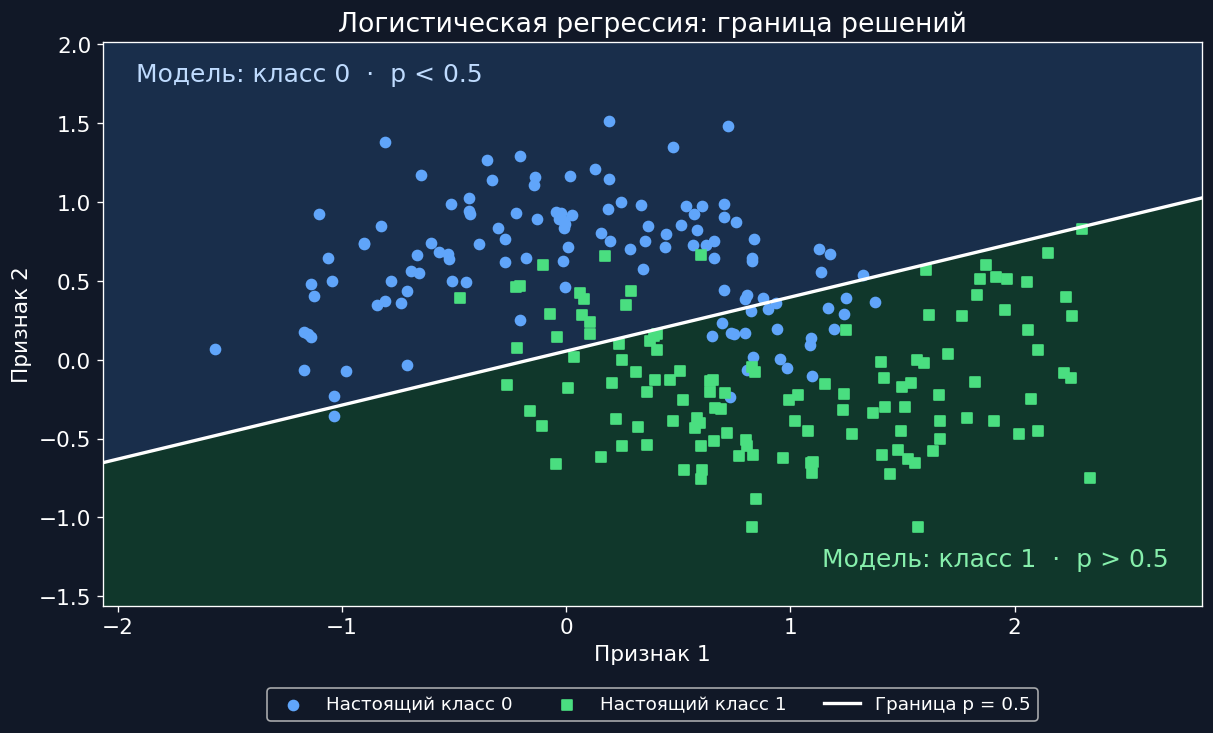

In [8]:
boundary_w1, boundary_w2 = logreg.coef_[0]
boundary_bias = logreg.intercept_[0]
print("Уравнение границы (коэффициенты округлены):")
print(f"{boundary_w1:.2f}·x₁ {boundary_w2:+.2f}·x₂ {boundary_bias:+.2f} = 0")

x1_grid = np.linspace(X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5, 240)
x2_grid = np.linspace(X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5, 200)
boundary_xx, boundary_yy = np.meshgrid(x1_grid, x2_grid)
boundary_grid = np.column_stack((boundary_xx.ravel(), boundary_yy.ravel()))
boundary_scores = logreg.decision_function(boundary_grid).reshape(boundary_xx.shape)

# Выразим x₂ через x₁ из уравнения прямой: w₁x₁ + w₂x₂ + b = 0.
# В нашей обученной модели w₂ не равен нулю.
boundary_y = -(boundary_w1 * x1_grid + boundary_bias) / boundary_w2

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
ax.contourf(
    boundary_xx, boundary_yy, boundary_scores,
    levels=[boundary_scores.min(), 0, boundary_scores.max()],
    colors=["#192E4B", "#10372B"],
)
ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
           color="#60A5FA", s=36, label="Настоящий класс 0")
ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
           color="#4ADE80", marker="s", s=36, label="Настоящий класс 1")
ax.plot(x1_grid, boundary_y, color="white", linewidth=2, label="Граница p = 0.5")
ax.text(0.03, 0.93, "Модель: класс 0  ·  p < 0.5", transform=ax.transAxes,
        color="#BFDBFE", fontsize=15)
ax.text(0.97, 0.07, "Модель: класс 1  ·  p > 0.5", transform=ax.transAxes,
        color="#86EFAC", fontsize=15, ha="right")
ax.set(xlim=(x1_grid[0], x1_grid[-1]), ylim=(x2_grid[0], x2_grid[-1]),
       xlabel="Признак 1", ylabel="Признак 2")
ax.set_title("Логистическая регрессия: граница решений")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=11)
plt.show()


Точки «чужого» класса на фоне — ошибки модели. Разделяющая граница задаёт правило ответа, но **не обязана идеально разделять реальные данные**. У наших двух полумесяцев закономерность нелинейная, а логрег на исходных признаках проводит прямую.

При одном признаке граница — точка на числовой оси, при двух — прямая, при трёх — плоскость. При большем числе признаков её называют **гиперплоскостью**: `w₁x₁ + … + wₙxₙ + b = 0`.

Сигмоида переводит score в вероятность, но не делает эту границу кривой. Если изменять порог при фиксированных коэффициентах, прямая сдвигается параллельно самой себе.


### Как измерить качество

**Accuracy** — доля верных меток: 9 верных ответов из 10 дают `0.9`.

**ROC-AUC** оценивает порядок вероятностей: насколько часто объект класса `1` получает больший score, чем объект класса `0`. `1.0` — идеальный порядок, около `0.5` — уровень случайного ранжирования. Ничья считается за половину успеха.

Для ROC-AUC передаём вероятности класса `1`, а для accuracy — метки. ROC-AUC не фиксирует порог `0.5`.

Log loss направляет обучение. Accuracy и ROC-AUC здесь помогают оценить уже полученную модель.


In [18]:
p_test = logreg.predict_proba(X_test)[:, 1]

print("Accuracy train:", round(logreg.score(X_train, y_train), 3))
print("Accuracy test:", round(logreg.score(X_test, y_test), 3))
print("ROC-AUC test:", round(roc_auc_score(y_test, p_test), 3))


Accuracy train: 0.841
Accuracy test: 0.876
ROC-AUC test: 0.931


> `predict_proba` — оценка вероятности моделью, а не гарантия правильности. Для классов `[0, 1]` sklearn выбирает `1` при `p > 0.5`; при точном равенстве — `0`. Для двух исходных признаков граница логистической регрессии — прямая.


## 3. Одно разбиение решающего дерева

Дерево задаёт вопросы вида `признак ≤ порог?`. Хороший вопрос делает дочерние группы более однородными.

Возьмём критерий Gini:

```text
Gini = 1 − p₀² − p₁²
```

`p₀` и `p₁` — доли классов внутри группы. Например, при равных долях Gini равен `1 − 0.5² − 0.5² = 0.5`. В чистой группе Gini равен `0`.

После разбиения учитываем **размеры ветвей**: маленькая чистая ветвь не должна перевешивать большую смешанную. Чем меньше взвешенный Gini, тем лучше порог.


In [10]:
x_small = np.array([1, 2, 3, 4, 5, 6, 7, 8])
y_small = np.array([0, 0, 0, 1, 0, 1, 1, 1])

print("Признак:", x_small)
print("Класс:", y_small)


Признак: [1 2 3 4 5 6 7 8]
Класс: [0 0 0 1 0 1 1 1]


Разделим объекты вопросом `x ≤ 3.5?`. Какие метки окажутся слева? Какая ветвь станет чистой?


![Ручной расчёт порога 3.5 по критерию Gini](attachment:gini-split.png)


In [11]:
def gini(labels):
    counts = np.bincount(labels, minlength=2)
    probabilities = counts / len(labels)
    return 1 - (probabilities ** 2).sum()


def split_gini(x, y, threshold):
    left = y[x <= threshold]
    right = y[x > threshold]
    if len(left) == 0 or len(right) == 0:
        return float("inf")  # Пустая ветвь — недопустимое разбиение.
    return (
        len(left) / len(y) * gini(left)
        + len(right) / len(y) * gini(right)
    )


threshold = 3.5
left = y_small[x_small <= threshold]
right = y_small[x_small > threshold]

print("Слева:", left, "Gini =", round(gini(left), 3))
print("Справа:", right, "Gini =", round(gini(right), 3))
print("Взвешенный Gini:", round(split_gini(x_small, y_small, threshold), 3))
print("Gini до разбиения:", round(gini(y_small), 3))


Слева: [0 0 0] Gini = 0.0
Справа: [1 0 1 1 1] Gini = 0.32
Взвешенный Gini: 0.2
Gini до разбиения: 0.5


Порог `3.5` улучшил Gini с `0.50` до `0.20`. Чтобы найти лучший порог, сравнивают кандидатов **между соседними различными значениями** признака: `1.5, 2.5, …, 7.5`. У разных порогов может быть одинаковое качество.


## 4. Дерево в sklearn

`DecisionTreeClassifier` выбирает лучшее разбиение в текущем узле, а затем повторяет процесс в его ветвях. Это локальный выбор: алгоритм не перебирает все возможные деревья.

**Лист** — узел без новых вопросов. Он выдаёт наиболее частый класс среди попавших в него обучающих объектов. Вероятность класса — его доля в листе.


In [13]:
tree_depth3 = DecisionTreeClassifier(
    criterion="gini", max_depth = 5, random_state=42
)
tree_depth3.fit(X_train, y_train)

print("Accuracy train:", round(tree_depth3.score(X_train, y_train), 3))
print("Accuracy test:", round(tree_depth3.score(X_test, y_test), 3))
print("Фактическая глубина:", tree_depth3.tree_.max_depth)
print("Количество узлов:", tree_depth3.tree_.node_count)


Accuracy train: 0.976
Accuracy test: 0.876
Фактическая глубина: 5
Количество узлов: 29


На рисунке `samples` — число обучающих объектов в узле, `class` — его ответ. Если условие верно, идём влево; иначе — вправо. `max_depth=3` разрешает не больше трёх вопросов на пути от корня до листа.


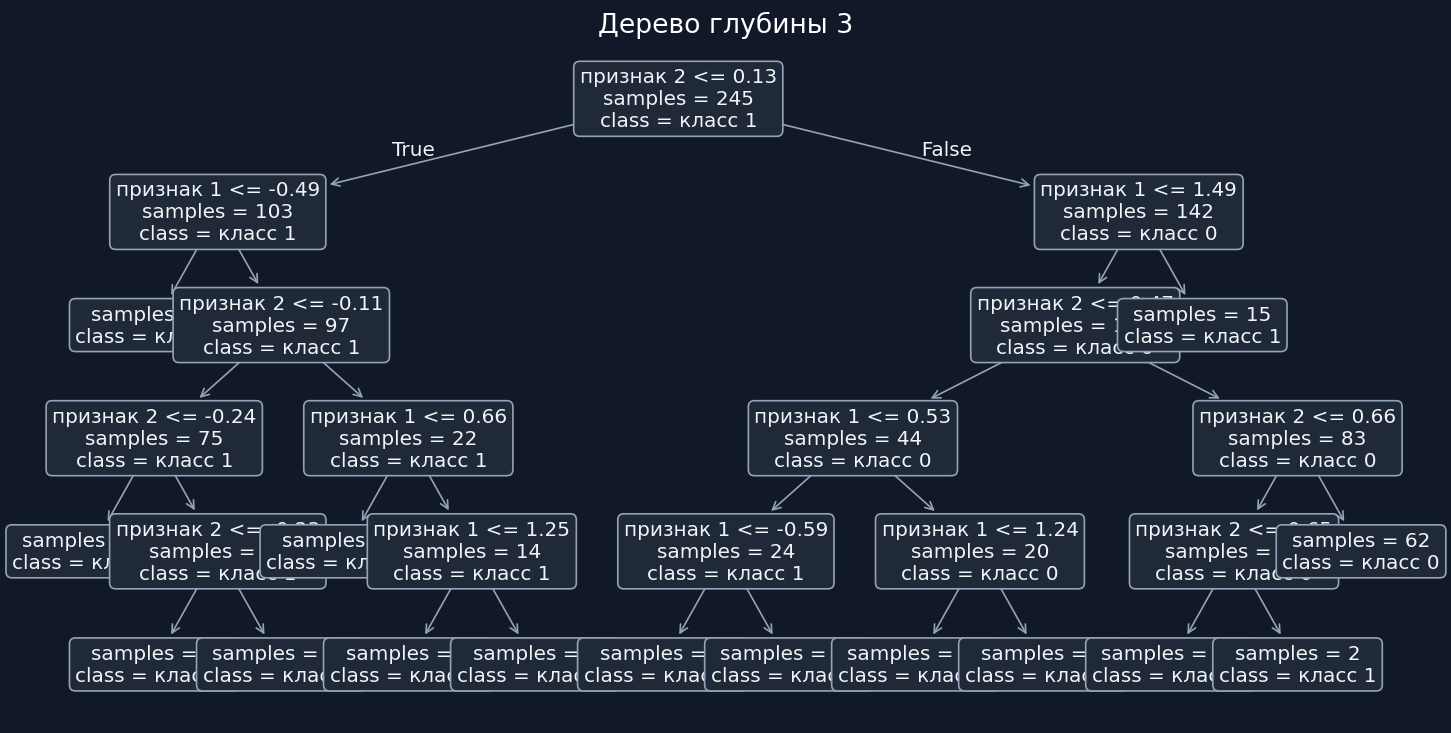

In [14]:
plt.figure(figsize=(12, 6), layout="constrained")
nodes = plot_tree(
    tree_depth3,
    feature_names=["признак 1", "признак 2"],
    class_names=["класс 0", "класс 1"],
    impurity=False,
    filled=False,
    rounded=True,
    precision=2,
    fontsize=12,
)
# Крупные подписи и контрастные узлы для тёмной темы.
for node in nodes:
    lines = node.get_text().splitlines()
    node.set_text("\n".join(line for line in lines if not line.startswith("value")))
    node.set_color("#F1F5F9")
    box = node.get_bbox_patch()
    if box is not None:
        box.set_facecolor("#1F2937")
        box.set_edgecolor("#94A3B8")
    if node.arrow_patch is not None:
        node.arrow_patch.set_edgecolor("#94A3B8")
plt.title("Дерево глубины 3")
plt.show()


![Границы логистической регрессии, неглубокого и глубокого дерева](attachment:decision-boundaries.png)


На трёх рисунках показаны **одни и те же обучающие точки**. Фон — класс, который модель предсказывает в этой части плоскости. Белая линия разделяет ответы `0` и `1`.

Логистическая регрессия проводит прямую границу. Дерево строит ступенчатые области. Глубокое дерево может выделять маленькие области для отдельных обучающих точек.


## 5. Глубина и переобучение

Увеличим `max_depth` и сравним качество на знакомом train и невидимом test.


In [15]:
depths = np.arange(1, 13)
train_accuracy = []
test_accuracy = []

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    train_accuracy.append(model.score(X_train, y_train))
    test_accuracy.append(model.score(X_test, y_test))

print("depth | train | test")
for depth, train_score, test_score in zip(depths, train_accuracy, test_accuracy):
    print(f"{depth:>5} | {train_score:.3f} | {test_score:.3f}")


depth | train | test
    1 | 0.812 | 0.762
    2 | 0.898 | 0.895
    3 | 0.898 | 0.895
    4 | 0.914 | 0.914
    5 | 0.976 | 0.876
    6 | 0.980 | 0.876
    7 | 0.992 | 0.857
    8 | 0.992 | 0.857
    9 | 1.000 | 0.848
   10 | 1.000 | 0.848
   11 | 1.000 | 0.848
   12 | 1.000 | 0.848


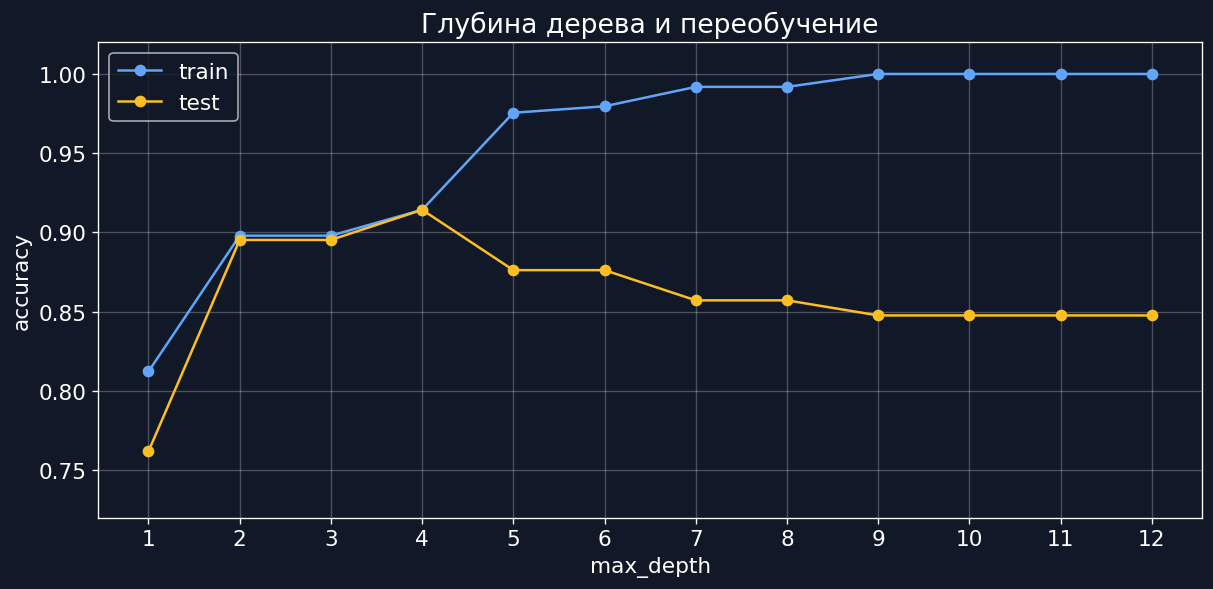

In [16]:
plt.figure(figsize=(10, 4.8), layout="constrained")
plt.plot(depths, train_accuracy, marker="o", color="#60A5FA", label="train")
plt.plot(depths, test_accuracy, marker="o", color="#FBBF24", label="test")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.title("Глубина дерева и переобучение")
plt.xticks(depths)
plt.ylim(0.72, 1.02)
plt.grid(alpha=0.25)
plt.legend()
plt.show()


В этом эксперименте качество на train доходит до `1.0`. Test-качество достигает максимума на глубине `4`, а затем в целом снижается. Падение не обязано происходить на каждом шаге.

**Переобучение:** модель всё лучше подстраивается под особенности и шум train, но хуже обобщает на новые объекты. Глубина `4` — результат именно этого эксперимента, а не универсальное правило.

В реальном проекте параметры модели выбирают по validation или кросс-валидации. Здесь test нужен для наглядной демонстрации разрыва.


## 6. Сравнение моделей

| Модель | Граница | Вероятность | Главный риск |
|---|---|---|---|
| Логистическая регрессия | линейная | `predict_proba` | недообучение на сложной границе |
| Решающее дерево | ступенчатая | доля класса в листе | переобучение при большой глубине |

Обе модели используют общий интерфейс sklearn:

```python
model.fit(X_train, y_train)
model.predict(X_test)
model.predict_proba(X_test)
```

Проверьте себя:

1. Модель дала вероятность `0.8`. Это метка класса или число для ROC-AUC?
2. Можно ли судить о качестве на новых объектах по accuracy train = `1.0`?
3. Обязательно ли более глубокое дерево даст лучший результат на новых данных?


## 7. Практика: вероятности логистической регрессии

Обучите `LogisticRegression` на `X_train, y_train`. Запишите в `practice_proba` вероятности класса `1` для `X_test`, а в `practice_pred` — предсказанные классы.

После заполнения ячейки запустите тесты.


In [19]:
practice_model = LogisticRegression(max_iter=1000)
practice_model.fit(X_train, y_train)
practice_proba = practice_model.predict_proba(X_test)[:, 1]
practice_pred = practice_model.predict(X_test)

In [20]:
if practice_model is None or practice_proba is None or practice_pred is None:
    print("Сначала заполните и выполните ячейку практики.")
else:
    assert practice_proba.shape == (len(X_test),), "Нужна одна вероятность на объект"
    assert practice_pred.shape == (len(X_test),)
    assert np.all((0 <= practice_proba) & (practice_proba <= 1))
    assert set(np.unique(practice_pred)) <= {0, 1}
    assert roc_auc_score(y_test, practice_proba) > 0.90, "Проверьте класс и обучение"
    assert np.allclose(practice_proba, practice_model.predict_proba(X_test)[:, 1])
    assert np.array_equal(practice_pred, practice_model.predict(X_test))
    print("Практика: тесты пройдены")
    print("ROC-AUC:", round(roc_auc_score(y_test, practice_proba), 3))


Практика: тесты пройдены
ROC-AUC: 0.931


<details>
<summary>Показать решение</summary>

```python
practice_model = LogisticRegression(max_iter=1000)
practice_model.fit(X_train, y_train)
practice_proba = practice_model.predict_proba(X_test)[:, 1]
practice_pred = practice_model.predict(X_test)
```

</details>


## Главное после урока

- логистическая регрессия: `линейный score → сигмоида → вероятность`;
- обучение меняет коэффициенты, уменьшая log loss на train;
- дерево: `признак ≤ порог?`, затем новые вопросы в ветвях;
- `max_depth` ограничивает сложность дерева;
- рост train-качества не гарантирует рост качества на новых данных;
- train нужен для обучения, test — для честной проверки.

### Контест

- I1: обучить логистическую регрессию и сдать вероятности;
- I2: найти лучший порог одного разбиения по одному признаку;
- I3*: собрать дерево из последовательных разбиений.

Следующее занятие — **«Как улучшить модель; старт кагла»**.
